# P12 - Analyse Exploratoire 

In [ ]:
from pathlib import Path
import pandas as pd
from jbtools import describoost

def describoost_dir(src_dir, **kwargs):
    """Lance describoost sur chaque .csv de src_dir. Retourne {nom_fichier: DataFrame}."""
    dfs = {}
    for f in sorted(Path(src_dir).glob("*.csv")):
        df = pd.read_csv(f)
        describoost(df, the_name=f.name, **kwargs)
        dfs[f.stem] = df
    return dfs

dfs = describoost_dir("../data_source")


==================== 🚀 DESCRIBOOST : crop_yield.csv ====================
Nbre de lignes  : 1000000 
Nbre de colonnes: 10 
Aucun doublon trouvé 

--- ANALYSE NUMÉRIQUE ---
                            count   mean    std    min    25%    50%    75%     max  skewsc  mean/md Minidist  NaNs  Nan% Remarque Suggestion
Rainfall_mm            1000000.00 549.98 259.85 100.00 324.89 550.12 774.74 1000.00    0.00     1.00     ▄▄▄▄  0.00  0.00        -          -
Temperature_Celsius    1000000.00  27.50   7.22  15.00  21.25  27.51  33.75   40.00    0.00     1.00     ▄▄▄▄  0.00  0.00        -          -
Days_to_Harvest        1000000.00 104.50  25.95  60.00  82.00 104.00 127.00  149.00    0.00     1.00     ▄▄▄▄  0.00  0.00        -          -
Yield_tons_per_hectare 1000000.00   4.65   1.70  -1.15   3.42   4.65   5.88    9.96   -0.10     1.00     ▄██▄  0.00  0.00        -          -

--- ANALYSE CATEGORIELLE ---
                     count unique    top    freq  freq%  cat.mean  cat.tp/mean  NaNs  Na

In [5]:
a = set(dfs["crop_yield"]["Crop"].unique())
b = set(dfs["yield_df"]["Item"].unique())

print("crop_yield :", sorted(a))
print("yield_df   :", sorted(b))
print("Communes   :", sorted(a & b))
print("Que crop_yield:", sorted(a - b))
print("Que yield_df  :", sorted(b - a))

crop_yield : ['Barley', 'Cotton', 'Maize', 'Rice', 'Soybean', 'Wheat']
yield_df   : ['Cassava', 'Maize', 'Plantains and others', 'Potatoes', 'Rice, paddy', 'Sorghum', 'Soybeans', 'Sweet potatoes', 'Wheat', 'Yams']
Communes   : ['Maize', 'Wheat']
Que crop_yield: ['Barley', 'Cotton', 'Rice', 'Soybean']
Que yield_df  : ['Cassava', 'Plantains and others', 'Potatoes', 'Rice, paddy', 'Sorghum', 'Soybeans', 'Sweet potatoes', 'Yams']


In [6]:
df = dfs["crop_yield"]
print(df.groupby("Irrigation_Used")["Yield_tons_per_hectare"].mean(), "\n")
print(df.groupby("Fertilizer_Used")["Yield_tons_per_hectare"].mean(), "\n")
print(df[["Rainfall_mm", "Temperature_Celsius", "Days_to_Harvest",
          "Yield_tons_per_hectare"]].corr()["Yield_tons_per_hectare"])

Irrigation_Used
False   4.05
True    5.25
Name: Yield_tons_per_hectare, dtype: float64 

Fertilizer_Used
False   3.90
True    5.40
Name: Yield_tons_per_hectare, dtype: float64 

Rainfall_mm               0.76
Temperature_Celsius       0.09
Days_to_Harvest          -0.00
Yield_tons_per_hectare    1.00
Name: Yield_tons_per_hectare, dtype: float64


In [7]:
df.groupby(pd.cut(df["Temperature_Celsius"], bins=6))["Yield_tons_per_hectare"].mean()

C:\Users\jacob\AppData\Local\Temp\ipykernel_23808\976874132.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(pd.cut(df["Temperature_Celsius"], bins=6))["Yield_tons_per_hectare"].mean()


Temperature_Celsius
(14.975, 19.167]   4.44
(19.167, 23.333]   4.52
(23.333, 27.5]     4.61
(27.5, 31.667]     4.69
(31.667, 35.833]   4.77
(35.833, 40.0]     4.86
Name: Yield_tons_per_hectare, dtype: float64

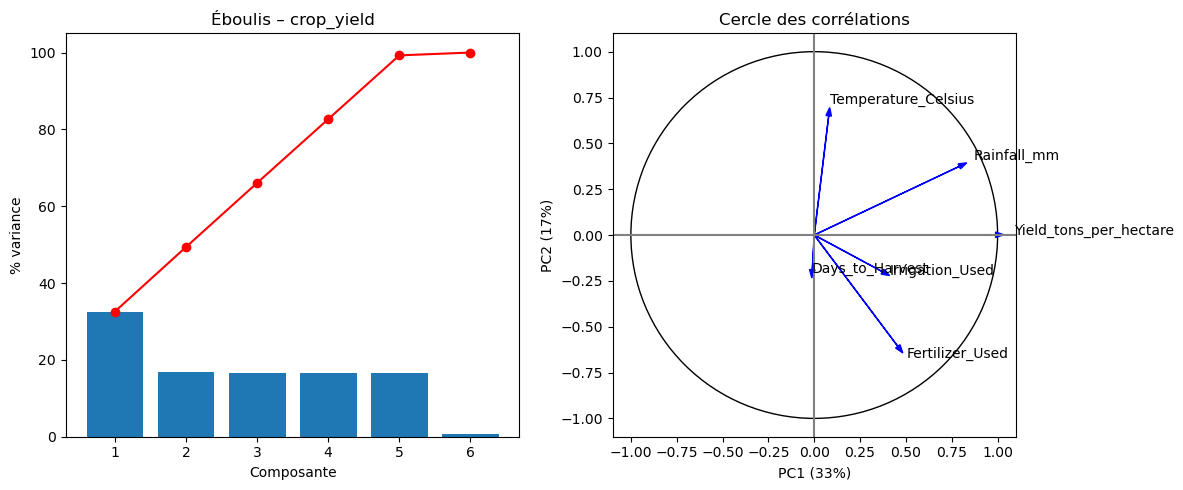

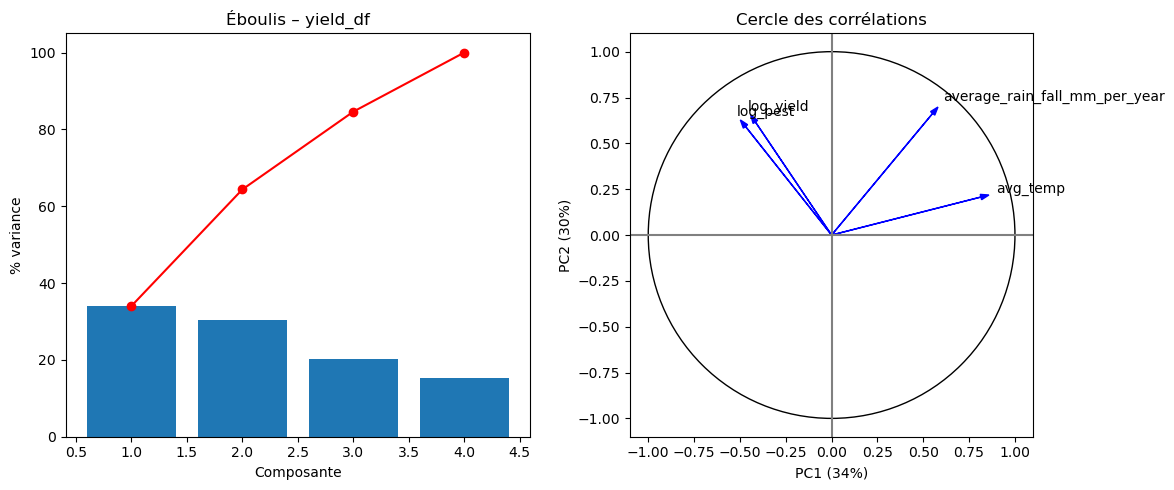

,n_components,None
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from pathlib import Path
datarep = Path("../data_source")

def run_pca(df, cols, title):
    X = StandardScaler().fit_transform(df[cols])
    pca = PCA().fit(X)
    ev = pca.explained_variance_ratio_

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    # Éboulis
    ax[0].bar(range(1, len(ev)+1), ev*100)
    ax[0].plot(range(1, len(ev)+1), ev.cumsum()*100, 'r-o')
    ax[0].set(title=f"Éboulis – {title}", xlabel="Composante", ylabel="% variance")
    # Cercle des corrélations (PC1/PC2)
    load = pca.components_[:2].T * np.sqrt(pca.explained_variance_[:2])
    ax[1].add_patch(plt.Circle((0, 0), 1, fill=False))
    for (x, y), c in zip(load, cols):
        ax[1].arrow(0, 0, x, y, head_width=0.03, color='b')
        ax[1].text(x*1.1, y*1.1, c)
    ax[1].set(xlim=(-1.1, 1.1), ylim=(-1.1, 1.1), title="Cercle des corrélations",
              xlabel=f"PC1 ({ev[0]:.0%})", ylabel=f"PC2 ({ev[1]:.0%})")
    ax[1].axhline(0, c='grey'); ax[1].axvline(0, c='grey'); ax[1].set_aspect('equal')
    plt.tight_layout(); plt.show()
    return pca

# crop_yield (échantillon pour la rapidité, seed fixé)
cy = pd.read_csv(datarep/"crop_yield.csv").sample(100_000, random_state=42)
cy[["Fertilizer_Used", "Irrigation_Used"]] = cy[["Fertilizer_Used", "Irrigation_Used"]].astype(int)
run_pca(cy, ["Rainfall_mm", "Temperature_Celsius", "Days_to_Harvest",
             "Fertilizer_Used", "Irrigation_Used", "Yield_tons_per_hectare"], "crop_yield")

# yield_df
yd = pd.read_csv(datarep/"yield_df.csv").drop(columns="Unnamed: 0")
yd["log_pest"] = np.log1p(yd["pesticides_tonnes"])
yd["log_yield"] = np.log1p(yd["hg/ha_yield"])
run_pca(yd, ["average_rain_fall_mm_per_year", "avg_temp", "log_pest", "log_yield"], "yield_df")

In [11]:
print(cy.corr(numeric_only=True)["Yield_tons_per_hectare"].sort_values())
print()
print(yd[["average_rain_fall_mm_per_year", "avg_temp", "log_pest", "log_yield"]].corr()["log_yield"])

Days_to_Harvest          -0.00
Temperature_Celsius       0.08
Irrigation_Used           0.36
Fertilizer_Used           0.44
Rainfall_mm               0.76
Yield_tons_per_hectare    1.00
Name: Yield_tons_per_hectare, dtype: float64

average_rain_fall_mm_per_year    0.07
avg_temp                        -0.12
log_pest                         0.19
log_yield                        1.00
Name: log_yield, dtype: float64


In [12]:
for name, d, t, y in [("crop_yield", cy, "Temperature_Celsius", "Yield_tons_per_hectare"),
                      ("yield_df", yd, "avg_temp", "log_yield")]:
    bins = pd.cut(d[t], bins=6)
    print(name); print(d.groupby(bins, observed=True)[y].agg(["mean", "count"]).round(2), "\n")
    

crop_yield
                     mean  count
Temperature_Celsius             
(14.975, 19.167]     4.46  16803
(19.167, 23.333]     4.54  16735
(23.333, 27.5]       4.62  16709
(27.5, 31.667]       4.68  16527
(31.667, 35.833]     4.77  16739
(35.833, 40.0]       4.87  16487 

yield_df
                  mean  count
avg_temp                     
(1.271, 6.192]   10.80    557
(6.192, 11.083]  11.01   2604
(11.083, 15.975] 10.93   2938
(15.975, 20.867] 10.66   7038
(20.867, 25.758] 10.51   7143
(25.758, 30.65]  10.64   7962 



In [13]:
full = pd.read_csv(datarep / "crop_yield.csv")
bins = pd.cut(full["Temperature_Celsius"], bins=[15,20,25,30,35,40], include_lowest=True)
print(full.groupby(bins, observed=True)["Yield_tons_per_hectare"].agg(["mean","count"]).round(3))

                     mean   count
Temperature_Celsius              
(14.999, 20.0]       4.45  200104
(20.0, 25.0]         4.55  199859
(25.0, 30.0]         4.65  199658
(30.0, 35.0]         4.75  200026
(35.0, 40.0]         4.85  200353


In [14]:
from scipy import stats

for c in ["Soil_Type", "Weather_Condition", "Region", "Crop"]:
    g = full.groupby(c)["Yield_tons_per_hectare"]
    print(g.agg(["mean", "std", "count"]).round(3))
    F, p = stats.f_oneway(*[x.values for _, x in g])
    eta2 = ((g.mean() - full["Yield_tons_per_hectare"].mean())**2 * g.count()).sum() \
           / ((full["Yield_tons_per_hectare"] - full["Yield_tons_per_hectare"].mean())**2).sum()
    print(f"-> eta² = {eta2:.4f}, p = {p:.2e}\n")

           mean  std   count
Soil_Type                   
Chalky     4.65 1.70  166779
Clay       4.64 1.70  166352
Loam       4.65 1.70  166795
Peaty      4.65 1.70  166283
Sandy      4.65 1.70  167119
Silt       4.65 1.70  166672
-> eta² = 0.0000, p = 8.06e-01

                   mean  std   count
Weather_Condition                   
Cloudy             4.65 1.70  332649
Rainy              4.65 1.70  333561
Sunny              4.65 1.70  333790
-> eta² = 0.0000, p = 5.25e-01

        mean  std   count
Region                   
East    4.65 1.70  249699
North   4.65 1.70  250173
South   4.65 1.70  250054
West    4.65 1.70  250074
-> eta² = 0.0000, p = 3.60e-01

         mean  std   count
Crop                      
Barley   4.65 1.70  166777
Cotton   4.65 1.70  166585
Maize    4.64 1.70  166824
Rice     4.65 1.70  166792
Soybean  4.65 1.70  166349
Wheat    4.65 1.70  166673
-> eta² = 0.0000, p = 3.16e-01



In [15]:
full.groupby(["Crop","Fertilizer_Used"])["Yield_tons_per_hectare"].mean().unstack()

Fertilizer_Used,False,True
Crop,,
Barley,3.89,5.41
Cotton,3.90,5.40
Maize,3.90,5.39
Rice,3.90,5.40
Soybean,3.91,5.40
Wheat,3.90,5.40


In [16]:
import statsmodels.api as sm

X = full[["Rainfall_mm", "Temperature_Celsius", "Days_to_Harvest",
          "Fertilizer_Used", "Irrigation_Used"]].astype(float)
X = sm.add_constant(X)
res = sm.OLS(full["Yield_tons_per_hectare"], X).fit()
print(res.summary())

                              OLS Regression Results                              
Dep. Variable:     Yield_tons_per_hectare   R-squared:                       0.913
Model:                                OLS   Adj. R-squared:                  0.913
Method:                     Least Squares   F-statistic:                 2.098e+06
Date:                  jeu., 29 oct. 2026   Prob (F-statistic):               0.00
Time:                            15:21:28   Log-Likelihood:            -7.2675e+05
No. Observations:                 1000000   AIC:                         1.454e+06
Df Residuals:                      999994   BIC:                         1.454e+06
Df Model:                               5                                         
Covariance Type:                nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------

In [17]:
import pandas as pd, statsmodels.api as sm

cats = ["Soil_Type", "Weather_Condition", "Region", "Crop"]
Xc = pd.get_dummies(full[cats], drop_first=True).astype(float)
Xn = full[["Rainfall_mm", "Temperature_Celsius", "Days_to_Harvest",
           "Fertilizer_Used", "Irrigation_Used"]].astype(float)
X = sm.add_constant(pd.concat([Xn, Xc], axis=1))
res2 = sm.OLS(full["Yield_tons_per_hectare"], X).fit()
print(res2.rsquared, res.rsquared)   # res = OLS précédent
print(res2.params.filter(like="_").round(4))

0.9129798166501246 0.9129780111739546
Rainfall_mm                0.01
Temperature_Celsius        0.02
Days_to_Harvest            0.00
Fertilizer_Used            1.50
Irrigation_Used            1.20
Soil_Type_Clay             0.00
Soil_Type_Loam             0.00
Soil_Type_Peaty            0.00
Soil_Type_Sandy            0.00
Soil_Type_Silt            -0.00
Weather_Condition_Rainy    0.00
Weather_Condition_Sunny    0.00
Region_North               0.00
Region_South              -0.00
Region_West               -0.00
Crop_Cotton               -0.00
Crop_Maize                -0.00
Crop_Rice                  0.00
Crop_Soybean              -0.00
Crop_Wheat                -0.00
dtype: float64


In [18]:
import statsmodels.formula.api as smf

# 1) Interactions : si les coefs d'interaction ≈ 0, l'effet est constant
m = smf.ols("Yield_tons_per_hectare ~ Fertilizer_Used*Rainfall_mm + Fertilizer_Used*Temperature_Celsius"
            " + Irrigation_Used*Rainfall_mm + Irrigation_Used*Temperature_Celsius"
            " + Fertilizer_Used*Irrigation_Used", data=full.astype({"Fertilizer_Used":int,"Irrigation_Used":int})).fit()
print(m.params.filter(like=":").round(4), m.rsquared)
print()

# 2) Dispersion de l'effet : si l'écart-type est identique avec/sans engrais, c'est un décalage pur
print(full.groupby("Fertilizer_Used")["Yield_tons_per_hectare"].std().round(3))

Fertilizer_Used:Rainfall_mm           -0.00
Fertilizer_Used:Temperature_Celsius   -0.00
Irrigation_Used:Rainfall_mm           -0.00
Irrigation_Used:Temperature_Celsius   -0.00
Fertilizer_Used:Irrigation_Used        0.00
dtype: float64 0.912978006829732

Fertilizer_Used
False   1.52
True    1.52
Name: Yield_tons_per_hectare, dtype: float64


In [ ]:
for name in ["yield", "pesticides", "rainfall", "temp"]:
    d = pd.read_csv(f"../data_source/{name}.csv")
    ycol = next(c for c in d.columns if c.lower().strip() == "year")
    print(name, 2003 in d[ycol].unique())

yield True
pesticides True
rainfall False
temp True


In [ ]:
r = pd.read_csv("../data_source/rainfall.csv")
r.columns = r.columns.str.strip()
print(r.columns.tolist())
print(sorted(r["Year"].unique()))                       # quelles années existent ?
a = r[r["Area"] == "Argentina"]
print(a.sort_values("Year").tail(30))                   # valeurs par année
print("pays à valeur unique:", (r.groupby("Area")[r.columns[-1]].nunique() == 1).mean())

['Area', 'Year', 'average_rain_fall_mm_per_year']
[np.int64(1985), np.int64(1986), np.int64(1987), np.int64(1989), np.int64(1990), np.int64(1991), np.int64(1992), np.int64(1993), np.int64(1994), np.int64(1995), np.int64(1996), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017)]
          Area  Year average_rain_fall_mm_per_year
218  Argentina  1986                           591
219  Argentina  1987                           591
220  Argentina  1989                           591
221  Argentina  1990                           591
222  Argentina  1991                           591
223  Argentina  1992                           591
224  Argentina  1993                           591
225  Argentina  1994                         